# AutoML para Previsão da Produção de Arroz na América do Sul

Disciplina: SCC0233, Aplicações de Aprendizado de Máquina e Mineração de Dados (ICMC-USP)
Atividade Prática 1: AutoML para Previsão da Produção de Arroz

## 1. Introdução e objetivo

Este notebook revisita o problema de Grion et al. (2026), *Predictive Modeling of Rice Production in South America Using
Machine Learning* (SBSI 2026, DOI 10.5753/sbsi.2026.248573). O artigo prevê a produção anual de arroz (t) de 12 países da
América do Sul a partir de dados agrícolas da FAOSTAT e climáticos da NASA POWER, comparando Regressão Linear, SVR e XGBoost
com hiperparâmetros escolhidos manualmente.

Aqui a seleção de modelos, os hiperparâmetros e a combinação de modelos ficam a cargo do **AutoGluon-Tabular**
(Erickson et al., 2020). Os resultados são comparados com os do artigo pelo MAPE, a métrica obrigatória, e por MAE, RMSE e R².

**Por que AutoGluon.**
- **Busca ampla.** Treina uma família ampla de modelos: LightGBM, CatBoost, XGBoost, Random Forest, Extra Trees, KNN,
  redes neurais e modelos lineares.
- **Ensemble por camadas.** Usa *bagging* com k-fold e *stack ensembling* em múltiplas camadas. É uma vantagem num dataset
  pequeno: cada modelo é avaliado fora da amostra e a combinação final é aprendida, não escolhida à mão.
- **Fácil de inspecionar.** O `leaderboard` mostra o erro de validação **e de teste** de cada modelo treinado, e há
  `feature_importance` por permutação e os pesos e hiperparâmetros de cada modelo. Isso permite abrir a caixa-preta.

Fontes usadas como ponto de partida:
- Artigo: <https://sol.sbc.org.br/index.php/sbsi/article/view/41343>
- Repositório oficial: <https://github.com/rgrion/mlarrozprevisao>

## 2. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

import autogluon.tabular
from autogluon.tabular import TabularPredictor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
MODELS_DIR = Path("AutogluonModels")   # modelos treinados (fora do git)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# estilo dos gráficos: fundo branco, grade discreta, cores fixas por série
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "figure.dpi": 110, "savefig.dpi": 150,
})

print("AutoGluon", autogluon.tabular.__version__, "| pandas", pd.__version__)

AutoGluon 1.6.3 | pandas 2.3.3


## 3. Carga de dados

O dataset já integra FAOSTAT e NASA POWER e vem do repositório oficial do artigo (`dataset_NASA_FAOSTAT.csv`). São 12 países,
de 2011 a 2023, num total de 156 observações. As colunas são `Pais`, `Year`, `Production (t)` (o alvo), `Area harvested (ha)`,
`Yield (kg/ha)`, `Temp_Media_C` e `Precipitacao_mm`. O arquivo é lido de `data/` e baixado automaticamente se não existir.

In [2]:
DATA_PATH = Path("data/dataset_NASA_FAOSTAT.csv")
RAW_URL = ("https://raw.githubusercontent.com/rgrion/mlarrozprevisao/main/"
           "Datasets_NASA_FAOSTAT/dataset_NASA_FAOSTAT.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"Dados carregados localmente de {DATA_PATH}")
else:
    df = pd.read_csv(RAW_URL)
    DATA_PATH.parent.mkdir(exist_ok=True)
    df.to_csv(DATA_PATH, index=False)
    print(f"Dados baixados de {RAW_URL} e salvos em {DATA_PATH}")

df["Pais"] = df["Pais"].astype("category")
df = df.sort_values(["Pais", "Year"]).reset_index(drop=True)
print(df.shape)
df.head(12)

Dados carregados localmente de data/dataset_NASA_FAOSTAT.csv
(156, 7)


,Pais,Year,Production (t),Area harvested (ha),Yield (kg/ha),Temp_Media_C,Precipitacao_mm
0,Argentina,2011,1748075.0,257445.0,6790.1,16.85,22.72
1,Argentina,2012,1567971.0,235372.0,6661.7,16.53,42.07
2,Argentina,2013,1563450.0,232700.0,6718.7,17.00,22.20
3,Argentina,2014,1581810.0,243200.0,6504.2,16.79,38.19
4,Argentina,2015,1558100.0,232590.0,6698.9,16.63,35.19
5,Argentina,2016,1404980.0,207740.0,6763.2,15.89,42.91
6,Argentina,2017,1328340.0,204100.0,6508.3,16.57,34.62
7,Argentina,2018,1367968.0,198170.0,6903.0,17.36,25.42
8,Argentina,2019,1189866.0,183285.0,6491.9,17.01,25.88
9,Argentina,2020,1222910.0,185300.0,6599.6,16.61,30.15


## 4. Análise exploratória

Estatísticas descritivas, dispersão entre países e correlação entre os atributos e o alvo, como na Seção 3.1 do artigo original.

In [3]:
NUM_COLS = ["Production (t)", "Area harvested (ha)", "Yield (kg/ha)", "Temp_Media_C", "Precipitacao_mm"]
df[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
Production (t),156.0,2.054479e+06,3.016262e+06,100557.00,537703.0000,1095656.00,1.774431e+06,13476994.00
Area harvested (ha),156.0,3.703261e+05,5.259805e+05,17945.00,144600.0000,182328.00,3.766670e+05,2752891.00
Yield (kg/ha),156.0,5.494595e+03,1.711069e+03,2400.90,4080.3000,5418.25,6.662475e+03,9397.00
Temp_Media_C,156.0,2.220756e+01,5.430215e+00,9.05,17.2625,24.82,2.605250e+01,30.91
Precipitacao_mm,156.0,5.344205e+01,3.436645e+01,0.30,29.9175,48.93,7.083750e+01,141.26


In [4]:
print("Países:", df["Pais"].nunique(), "| Anos:", df["Year"].min(), "-", df["Year"].max())
print("Observações por país:", df.groupby("Pais", observed=True).size().unique())
print("Valores ausentes:", int(df.isna().sum().sum()))

Países: 12 | Anos: 2011 - 2023
Observações por país: [13]
Valores ausentes: 0


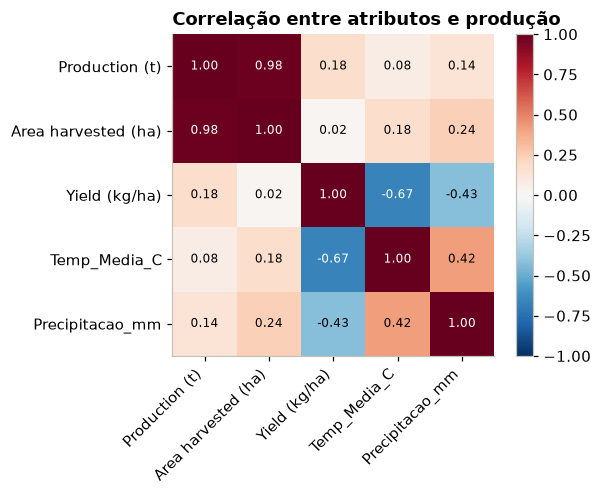

In [5]:
corr = df[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(5.8, 4.6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(NUM_COLS)), NUM_COLS)
ax.grid(False)
for i in range(len(NUM_COLS)):
    for j in range(len(NUM_COLS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Correlação entre atributos e produção")
fig.tight_layout(); fig.savefig(FIG / "correlacao.png", bbox_inches="tight"); plt.show()

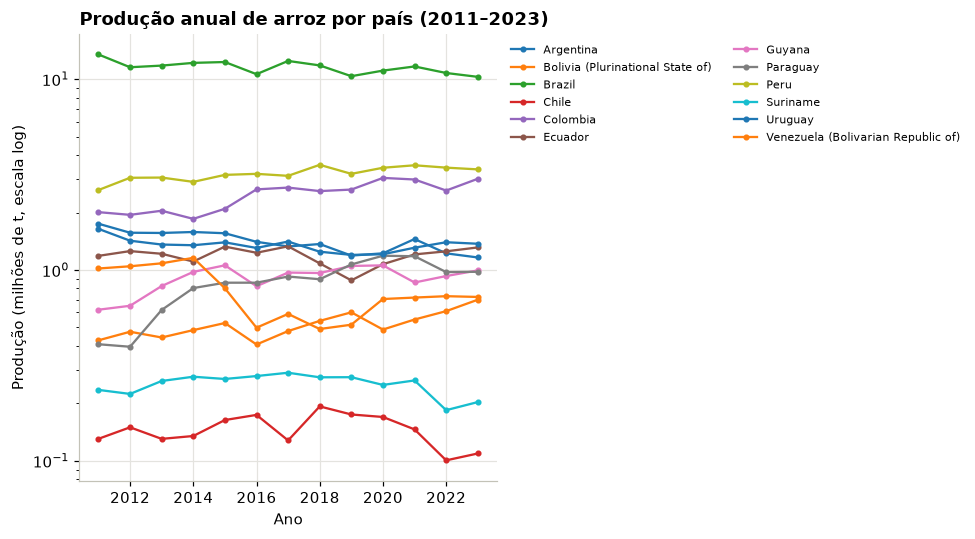

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for pais, g in df.groupby("Pais", observed=True):
    ax.plot(g["Year"], g["Production (t)"] / 1e6, marker="o", ms=3, label=pais, linewidth=1.5)
ax.set_xlabel("Ano"); ax.set_ylabel("Produção (milhões de t, escala log)"); ax.set_yscale("log")
ax.set_title("Produção anual de arroz por país (2011–2023)")
ax.legend(fontsize=7.5, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); fig.savefig(FIG / "producao_por_pais.png", bbox_inches="tight"); plt.show()

A produção é muito assimétrica: o Brasil produz uma ordem de grandeza a mais que os demais, e Suriname e Guiana ficam no outro
extremo. `Area harvested (ha)` é o atributo mais correlacionado com a produção. Não há valores ausentes. Com só 13 observações
por país, o identificador do país pode virar um atalho para o modelo, e isso é verificado na Seção 7.

## 5. Preparação dos dados

A configuração segue o artigo original (Seções 3.4 e 3.6):

- **Alvo:** `Production (t)`.
- **Atributos agrícolas:** `Pais`, `Year`, `Area harvested (ha)` e `Yield (kg/ha)`.
- **Atributos com clima:** os agrícolas mais `Temp_Media_C` e `Precipitacao_mm`.
- **Cenário A (holdout):** treino de 2011 a 2020 e teste de 2021 a 2023. É a janela de 10 anos e o horizonte de 3 anos
  que os autores usam na integração com o clima (Seção 3.6).
- **Cenário B (validação cruzada):** `KFold` com k=5 sobre 2011 a 2023.
- **Tratamento das variáveis:** `Pais` entra como categórica, e o AutoGluon faz o pré-processamento sozinho
  (codificação, tipos). Não há normalização manual.

In [7]:
FEATURES_AGRI = ["Pais", "Year", "Area harvested (ha)", "Yield (kg/ha)"]
FEATURES_CLIMA = FEATURES_AGRI + ["Temp_Media_C", "Precipitacao_mm"]
FEATURE_SETS = {"agri": FEATURES_AGRI, "clima": FEATURES_CLIMA}
TARGET = "Production (t)"

train_mask, test_mask = df["Year"] <= 2020, df["Year"] > 2020
print("Treino:", train_mask.sum(), "obs. | Teste:", test_mask.sum(), "obs.")


def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)


def regression_report(y_true, y_pred):
    return {"MAPE (%)": mape(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5, "R2": r2_score(y_true, y_pred)}

Treino: 120 obs. | Teste: 36 obs.


## 6. AutoML, Cenário A (holdout 2011–2020 → 2021–2023)

O AutoGluon roda duas vezes, sem e com clima, para isolar o efeito da integração climática (Seções 4.5 e 4.8 do artigo).

| Parâmetro | Valor | Por quê |
|---|---|---|
| `eval_metric` | `mean_absolute_percentage_error` | otimiza diretamente a métrica do artigo |
| `presets` | `best_quality` | *bagging* em k-fold e *stacking* em várias camadas |
| `time_limit` | 120 s | escolhido no estudo de sensibilidade (Seção 8) |

O teste (2021–2023) nunca é visto no treino. Ele só entra depois, para medir o erro de cada modelo no `leaderboard`.

In [8]:
PRESET, TIME_LIMIT = "best_quality", 120


def fit_autogluon(train_df, feats, name, preset=PRESET, time_limit=TIME_LIMIT, seed=RANDOM_SEED):
    """Treina um TabularPredictor do zero; devolve o predictor e o tempo de treino (s)."""
    t0 = time.time()
    predictor = TabularPredictor(
        label=TARGET, problem_type="regression", eval_metric="mean_absolute_percentage_error",
        path=str(MODELS_DIR / name), verbosity=0,
    ).fit(
        train_df[feats + [TARGET]], presets=preset, time_limit=time_limit,
        ag_args_fit={"random_seed": seed}, ag_args_ensemble={"model_random_seed": seed},
    )
    return predictor, time.time() - t0


predictors_A, fit_time_A = {}, {}
for label, feats in FEATURE_SETS.items():
    predictors_A[label], fit_time_A[label] = fit_autogluon(df[train_mask], feats, f"A_{label}")
    p = predictors_A[label]
    print(f"[{label}] melhor modelo: {p.model_best} | modelos treinados: {len(p.model_names())} "
          f"| tempo: {fit_time_A[label]:.0f}s")

[agri] melhor modelo: WeightedEnsemble_L3 | modelos treinados: 19 | tempo: 121s


[clima] melhor modelo: WeightedEnsemble_L3 | modelos treinados: 18 | tempo: 121s


## 7. Inspeção do processo (abrindo a caixa-preta)

### 7.1 Leaderboard: validação e teste de cada modelo

O AutoGluon devolve o **MAPE de validação** de cada modelo treinado, calculado *out-of-fold* no bagging, e também o
**MAPE no teste** (2021–2023). Assim dá para ver se o modelo escolhido pela validação é de fato o melhor fora da amostra.

In [9]:
def leaderboard_table(predictor, feats):
    lb = predictor.leaderboard(df.loc[test_mask, feats + [TARGET]], silent=True)
    return pd.DataFrame({
        "modelo": lb["model"],
        "camada": lb["stack_level"],
        "MAPE validação (%)": -100 * lb["score_val"],
        "MAPE teste (%)": -100 * lb["score_test"],
        "tempo de treino (s)": lb["fit_time"],
        "tempo de predição no teste (s)": lb["pred_time_test"],
    }).sort_values("MAPE validação (%)").reset_index(drop=True)


leaderboards_A = {label: leaderboard_table(predictors_A[label], feats) for label, feats in FEATURE_SETS.items()}
leaderboards_A["agri"].head(15).style.format(precision=2).hide(axis="index")

modelo,camada,MAPE validação (%),MAPE teste (%),tempo de treino (s),tempo de predição no teste (s)
WeightedEnsemble_L3,3,4.34,7.20,34.77,0.36
WeightedEnsemble_L2,2,4.41,6.89,11.82,0.09
RandomForestMSE_BAG_L2,2,5.24,8.93,18.44,0.33
ExtraTreesMSE_BAG_L1,1,5.49,8.65,0.23,0.03
RandomForestMSE_BAG_L1,1,8.18,11.67,0.31,0.03
NeuralNetTorch_BAG_L1,1,8.51,25.44,6.89,0.03
XGBoost_BAG_L1,1,8.68,10.01,1.97,0.04
LightGBMLarge_BAG_L1,1,9.02,12.20,2.08,0.02
NeuralNetTorch_r79_BAG_L1,1,9.81,11.60,6.22,0.03
CatBoost_BAG_L2,2,10.36,15.71,34.39,0.33


In [10]:
leaderboards_A["clima"].head(15).style.format(precision=2).hide(axis="index")

modelo,camada,MAPE validação (%),MAPE teste (%),tempo de treino (s),tempo de predição no teste (s)
WeightedEnsemble_L3,3,5.44,8.99,36.53,0.26
WeightedEnsemble_L2,2,5.84,8.02,9.15,0.09
RandomForestMSE_BAG_L2,2,6.41,10.36,21.76,0.25
ExtraTreesMSE_BAG_L1,1,6.57,9.60,0.15,0.03
NeuralNetTorch_r79_BAG_L1,1,8.44,9.71,8.58,0.03
RandomForestMSE_BAG_L1,1,8.53,9.23,0.39,0.03
XGBoost_BAG_L1,1,9.62,9.97,2.16,0.04
NeuralNetTorch_BAG_L1,1,10.21,20.99,7.89,0.04
CatBoost_BAG_L2,2,10.34,16.48,36.05,0.23
CatBoost_r177_BAG_L1,1,19.17,19.71,3.31,0.01


In [11]:
# O modelo escolhido pela validação também é o melhor no teste?
for label, lb in leaderboards_A.items():
    chosen = predictors_A[label].model_best
    rank = lb.sort_values("MAPE teste (%)").reset_index(drop=True)
    pos = rank.index[rank["modelo"] == chosen][0] + 1
    print(f"[{label}] escolhido: {chosen} | MAPE teste {lb.set_index('modelo').loc[chosen, 'MAPE teste (%)']:.2f}% "
          f"| posição no teste: {pos}º de {len(lb)} | melhor no teste: {rank.loc[0, 'modelo']} "
          f"({rank.loc[0, 'MAPE teste (%)']:.2f}%)")

[agri] escolhido: WeightedEnsemble_L3 | MAPE teste 7.20% | posição no teste: 2º de 19 | melhor no teste: WeightedEnsemble_L2 (6.89%)
[clima] escolhido: WeightedEnsemble_L3 | MAPE teste 8.99% | posição no teste: 2º de 18 | melhor no teste: WeightedEnsemble_L2 (8.02%)


### 7.2 O modelo final: composição do ensemble e hiperparâmetros

O modelo final é um `WeightedEnsemble`, uma média ponderada dos modelos de base, com pesos ajustados nas predições
*out-of-fold*. A tabela mostra os pesos e, para cada modelo de base, os principais hiperparâmetros escolhidos.

In [12]:
def ensemble_weights(predictor):
    model = predictor._trainer.load_model(predictor.model_best)
    weights = model._get_model_weights() if hasattr(model, "_get_model_weights") else {predictor.model_best: 1.0}
    return pd.Series({k: float(v) for k, v in weights.items()}).sort_values(ascending=False)


def child_hyperparameters(predictor, name):
    info = predictor.info()["model_info"][name]
    children = info.get("children_info") or {}
    hp = next(iter(children.values()))["hyperparameters"] if children else info["hyperparameters"]
    return {k: v for k, v in hp.items() if not isinstance(v, (dict, list)) and k not in ("n_jobs", "num_threads")}


for label, p in predictors_A.items():
    w = ensemble_weights(p)
    print(f"=== Cenário A | {label} | {p.model_best} ===")
    print((w.round(3)).to_string())
    print()

=== Cenário A | agri | WeightedEnsemble_L3 ===
ExtraTreesMSE_BAG_L1      0.562
NeuralNetTorch_BAG_L1     0.188
RandomForestMSE_BAG_L2    0.125
LightGBMLarge_BAG_L1      0.062
CatBoost_BAG_L2           0.062

=== Cenário A | clima | WeightedEnsemble_L3 ===
ExtraTreesMSE_BAG_L1         0.36
RandomForestMSE_BAG_L2       0.32
NeuralNetTorch_r79_BAG_L1    0.20
CatBoost_BAG_L2              0.12



In [13]:
for label, p in predictors_A.items():
    top = ensemble_weights(p).index[0]
    print(f"[{label}] modelo de maior peso: {top}")
    print(json.dumps(child_hyperparameters(p, top), indent=2, default=str))

[agri] modelo de maior peso: ExtraTreesMSE_BAG_L1


{
  "n_estimators": 300,
  "max_leaf_nodes": 15000,
  "bootstrap": true,
  "criterion": "squared_error",
  "random_state": 42
}
[clima] modelo de maior peso: ExtraTreesMSE_BAG_L1


{
  "n_estimators": 300,
  "max_leaf_nodes": 15000,
  "bootstrap": true,
  "criterion": "squared_error",
  "random_state": 42
}


### 7.3 Importância dos atributos (permutação no teste)

A pergunta é se o modelo aprendeu relações agrícolas ou se usa o país como atalho. A importância por permutação mede quanto o
MAPE de teste piora quando cada atributo é embaralhado.

In [14]:
importances_A = {}
for label, feats in FEATURE_SETS.items():
    fi = predictors_A[label].feature_importance(df.loc[test_mask, feats + [TARGET]], num_shuffle_sets=10,
                                                 silent=True)
    importances_A[label] = (100 * fi["importance"]).rename("piora do MAPE (p.p.)")
pd.DataFrame(importances_A).sort_values("agri", ascending=False).round(2)

,agri,clima
Area harvested (ha),260.10,222.87
Yield (kg/ha),29.40,26.14
Pais,14.33,28.62
Year,0.37,0.03
Precipitacao_mm,NaN,4.32
Temp_Media_C,NaN,12.21


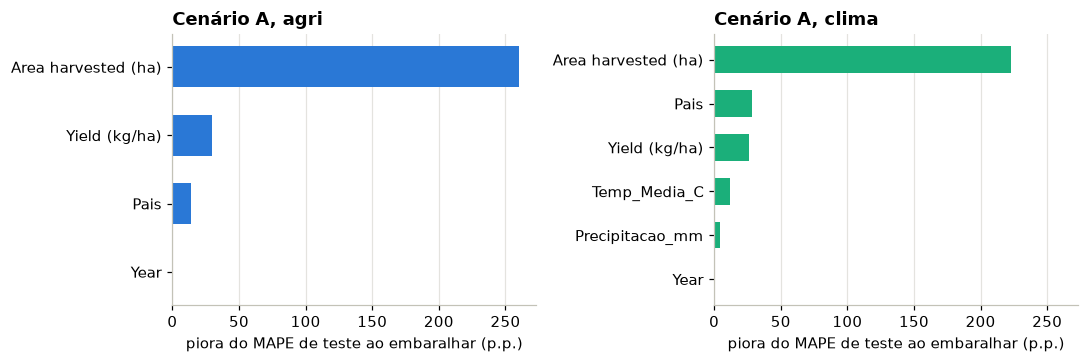

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, (label, imp) in zip(axes, importances_A.items()):
    imp = imp.sort_values()
    ax.barh(imp.index, imp.values, color=BLUE if label == "agri" else AQUA, height=0.6)
    ax.set_title(f"Cenário A, {label}"); ax.set_xlabel("piora do MAPE de teste ao embaralhar (p.p.)")
    ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "importancia_atributos.png", bbox_inches="tight"); plt.show()

### 7.4 Baseline manual: Regressão Linear padronizada

Serve como referência dentro do próprio notebook, com os mesmos dados e o mesmo split: one-hot no país,
`StandardScaler` e `LinearRegression`.

In [16]:
def fit_manual_linear(feats):
    X_train = pd.get_dummies(df.loc[train_mask, feats], columns=["Pais"], drop_first=True)
    X_test = pd.get_dummies(df.loc[test_mask, feats], columns=["Pais"], drop_first=True).reindex(
        columns=X_train.columns, fill_value=0)
    scaler = StandardScaler().fit(X_train)
    lr = LinearRegression().fit(scaler.transform(X_train), df.loc[train_mask, TARGET])
    return regression_report(df.loc[test_mask, TARGET], lr.predict(scaler.transform(X_test)))


manual_lr = pd.DataFrame({label: fit_manual_linear(feats) for label, feats in FEATURE_SETS.items()}).T
manual_lr.round(2)

,MAPE (%),MAE,RMSE,R2
agri,24.34,150269.31,202251.33,0.99
clima,24.98,152779.40,202018.36,0.99


## 8. Sensibilidade do processo: preset × tempo

O `preset` e o `time_limit` são decisões do processo, não hiperparâmetros de um modelo. Por isso foram testados de forma
explícita no Cenário A agrícola:
- **`medium_quality`:** sem bagging, com validação em holdout interno;
- **`high_quality`:** bagging e stacking, mais rápido na inferência;
- **`best_quality`:** bagging e stacking completos.

Cada preset roda com 30, 60 e 120 s.

In [17]:
SENS_PRESETS = ["medium_quality", "high_quality", "best_quality"]
SENS_LIMITS = [30, 60, 120]
sens_rows = []
X_test_agri, y_test_agri = df.loc[test_mask, FEATURES_AGRI], df.loc[test_mask, TARGET]
for preset in SENS_PRESETS:
    for limit in SENS_LIMITS:
        if preset == PRESET and limit == TIME_LIMIT:
            p, t = predictors_A["agri"], fit_time_A["agri"]   # já treinado na Seção 6
        else:
            p, t = fit_autogluon(df[train_mask], FEATURES_AGRI, f"sens_{preset}_{limit}", preset, limit)
        sens_rows.append({"preset": preset, "time_limit (s)": limit, "tempo real (s)": t,
                          "MAPE teste (%)": mape(y_test_agri, p.predict(X_test_agri)),
                          "modelos treinados": len(p.model_names()), "melhor modelo": p.model_best})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.style.format(precision=2).hide(axis="index")

preset,time_limit (s),tempo real (s),MAPE teste (%),modelos treinados,melhor modelo
medium_quality,30,20.79,6.05,10,WeightedEnsemble_L2
medium_quality,60,22.53,6.05,10,WeightedEnsemble_L2
medium_quality,120,22.87,6.05,10,WeightedEnsemble_L2
high_quality,30,33.94,11.66,14,WeightedEnsemble_L2_FULL
high_quality,60,66.25,8.75,20,WeightedEnsemble_L2_FULL
high_quality,120,126.12,7.11,32,WeightedEnsemble_L3_FULL
best_quality,30,34.02,11.54,7,WeightedEnsemble_L2
best_quality,60,60.14,8.54,12,WeightedEnsemble_L3
best_quality,120,120.80,7.20,19,WeightedEnsemble_L3


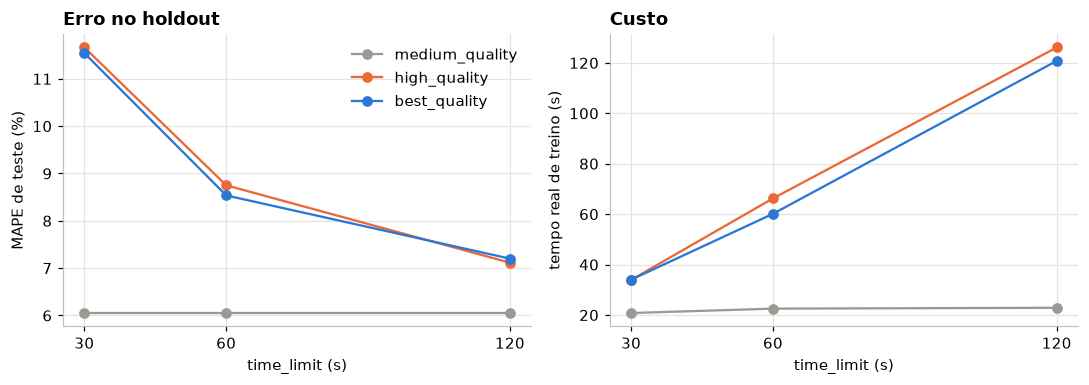

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for preset, color in zip(SENS_PRESETS, [GRAY, ORANGE, BLUE]):
    s = sensitivity[sensitivity["preset"] == preset]
    a1.plot(s["time_limit (s)"], s["MAPE teste (%)"], marker="o", color=color, label=preset)
    a2.plot(s["time_limit (s)"], s["tempo real (s)"], marker="o", color=color, label=preset)
a1.set_xlabel("time_limit (s)"); a1.set_ylabel("MAPE de teste (%)"); a1.set_title("Erro no holdout")
a2.set_xlabel("time_limit (s)"); a2.set_ylabel("tempo real de treino (s)"); a2.set_title("Custo")
a1.set_xticks(SENS_LIMITS); a2.set_xticks(SENS_LIMITS); a1.legend()
fig.tight_layout(); fig.savefig(FIG / "sensibilidade_presets.png", bbox_inches="tight"); plt.show()

**O que a sensibilidade mostra.**
- **`best_quality` e `high_quality` melhoram com o tempo.** Com 30 s, mal começam o stacking (MAPE de cerca de 11,6%). Em 120 s chegam a 7,1–7,2%, com 19 a 32 modelos treinados.
- **O `medium_quality` termina em cerca de 22 s em qualquer orçamento**, porque não faz bagging, e teve o menor MAPE de teste nesta execução (6,05%).
- **Essa diferença é menor que o ruído.** Com 36 pontos de teste, a variação entre sementes do próprio `best_quality` vai de 6,0% a 8,1% (Seção 9).
- **O preset não foi escolhido pelo teste**, porque isso seria usar o teste para selecionar o modelo. A escolha foi o `best_quality` com 120 s:
  - é o preset com validação *out-of-fold* em todos os modelos, a estimativa mais confiável com 120 linhas;
  - 120 s é o ponto em que o erro para de cair de forma acentuada sem tornar caras as 10 execuções da validação cruzada.


## 9. Variabilidade entre sementes

Com 156 observações, uma única execução pode ser sorte. O Cenário A é repetido com 3 sementes nos modelos (42, 7 e 2026).
A divisão dos folds do bagging fica fixa, e a semente varia a inicialização e a amostragem de cada modelo.

In [19]:
SEEDS = [42, 7, 2026]
seed_rows = []
for label, feats in FEATURE_SETS.items():
    for seed in SEEDS:
        if seed == RANDOM_SEED:
            p = predictors_A[label]
        else:
            p, _ = fit_autogluon(df[train_mask], feats, f"seed_{label}_{seed}", seed=seed)
        seed_rows.append({"features": label, "seed": seed, "melhor modelo": p.model_best,
                          "MAPE teste (%)": mape(df.loc[test_mask, TARGET], p.predict(df.loc[test_mask, feats]))})
seeds_df = pd.DataFrame(seed_rows)
display(seeds_df.round(2))
seed_summary = seeds_df.groupby("features")["MAPE teste (%)"].agg(["mean", "std", "min", "max"]).round(2)
seed_summary

,features,seed,melhor modelo,MAPE teste (%)
0,agri,42,WeightedEnsemble_L3,7.20
1,agri,7,WeightedEnsemble_L3,6.03
2,agri,2026,WeightedEnsemble_L3,8.14
3,clima,42,WeightedEnsemble_L3,8.99
4,clima,7,WeightedEnsemble_L3,6.93
5,clima,2026,WeightedEnsemble_L3,8.37


,mean,std,min,max
features,,,,
agri,7.12,1.06,6.03,8.14
clima,8.09,1.06,6.93,8.99


## 10. Avaliação, Cenário A (holdout 2021–2023)

As métricas são o MAPE (obrigatório), o MAE, o RMSE e o R², agregados e por ano. Elas são comparáveis às Figuras 5, 6 e 11 do
artigo original.

In [20]:
results_A, per_year_A, per_country_A = {}, {}, {}
for label, feats in FEATURE_SETS.items():
    p = predictors_A[label]
    test = df.loc[test_mask].copy()
    test["pred"] = p.predict(test[feats])
    results_A[label] = regression_report(test[TARGET], test["pred"])
    per_year_A[label] = pd.DataFrame([{"Year": y, **regression_report(g[TARGET], g["pred"])}
                                      for y, g in test.groupby("Year")])
    per_country_A[label] = pd.DataFrame([{"Pais": c, **regression_report(g[TARGET], g["pred"])}
                                         for c, g in test.groupby("Pais", observed=True)])
pd.DataFrame(results_A).T.round(3)

,MAPE (%),MAE,RMSE,R2
agri,7.20,123897.227,219960.178,0.994
clima,8.99,124449.322,215316.372,0.994


In [21]:
pd.concat({k: v.set_index("Year")["MAPE (%)"] for k, v in per_year_A.items()}, axis=1).round(2)

,agri,clima
Year,,
2021,4.96,6.11
2022,10.22,11.90
2023,6.42,8.96


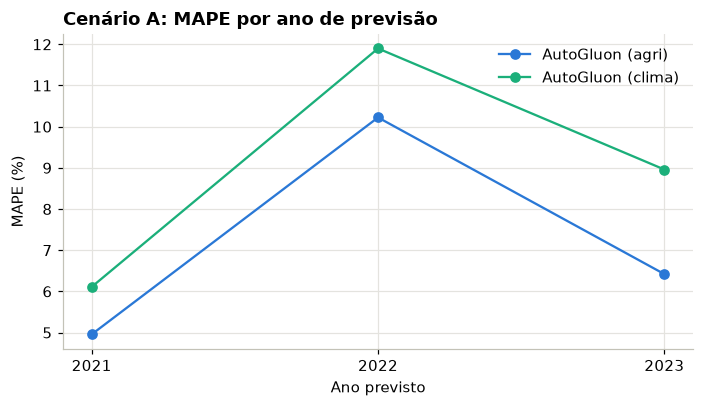

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for label, color in [("agri", BLUE), ("clima", AQUA)]:
    py = per_year_A[label]
    ax.plot(py["Year"], py["MAPE (%)"], marker="o", color=color, label=f"AutoGluon ({label})")
ax.set_xlabel("Ano previsto"); ax.set_ylabel("MAPE (%)"); ax.set_xticks(sorted(df.loc[test_mask, "Year"].unique()))
ax.set_title("Cenário A: MAPE por ano de previsão"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "mape_por_ano_A.png", bbox_inches="tight"); plt.show()

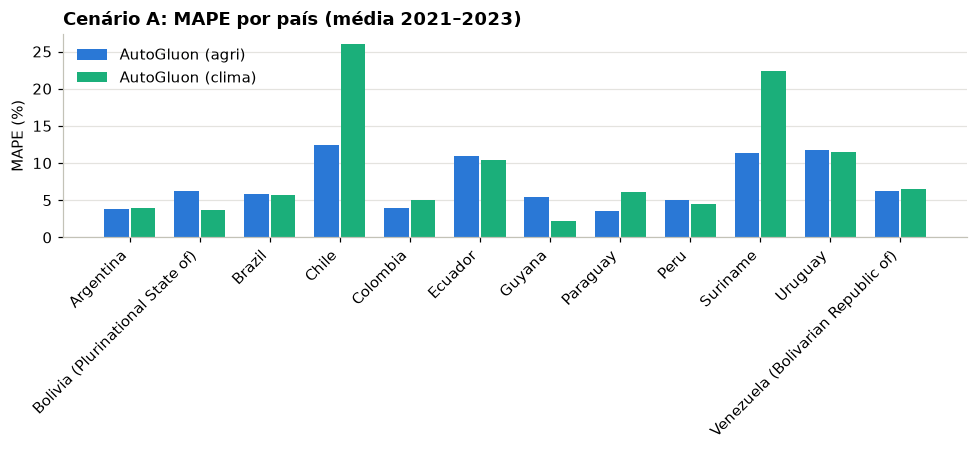

,agri,clima
Pais,,
Argentina,3.81,3.90
Bolivia (Plurinational State of),6.23,3.69
Brazil,5.82,5.64
Chile,12.45,26.03
Colombia,3.90,5.00
Ecuador,10.96,10.45
Guyana,5.46,2.15
Paraguay,3.54,6.13
Peru,5.03,4.49


In [23]:
fig, ax = plt.subplots(figsize=(9, 4.2))
countries = per_country_A["agri"]["Pais"].astype(str)
x, w = np.arange(len(countries)), 0.38
ax.bar(x - w / 2, per_country_A["agri"]["MAPE (%)"], w * 0.92, color=BLUE, label="AutoGluon (agri)")
ax.bar(x + w / 2, per_country_A["clima"]["MAPE (%)"], w * 0.92, color=AQUA, label="AutoGluon (clima)")
ax.set_xticks(x, countries, rotation=45, ha="right"); ax.set_ylabel("MAPE (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Cenário A: MAPE por país (média 2021–2023)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "mape_por_pais_A.png", bbox_inches="tight"); plt.show()
pd.concat({k: v.set_index("Pais")["MAPE (%)"] for k, v in per_country_A.items()}, axis=1).round(2)

## 11. AutoML, Cenário B (validação cruzada k=5)

A cada fold, um `TabularPredictor` novo é treinado do zero e avaliado no fold de teste. O resultado é o MAPE médio com o
desvio-padrão, como no artigo original. Como cada fold tem menos dados e são 10 execuções, o orçamento cai para 60 s por fold.

In [24]:
TIME_LIMIT_B = 60


def kfold_autogluon(feats, label, k=5):
    kf = KFold(n_splits=k, shuffle=True, random_state=RANDOM_SEED)
    rows = []
    for i, (tr, te) in enumerate(kf.split(df)):
        p, t = fit_autogluon(df.iloc[tr], feats, f"B_{label}_fold{i}", time_limit=TIME_LIMIT_B)
        rows.append({"fold": i, "melhor modelo": p.model_best, "tempo (s)": t,
                     **regression_report(df.iloc[te][TARGET], p.predict(df.iloc[te][feats]))})
    return pd.DataFrame(rows)


cv_results = {label: kfold_autogluon(feats, label) for label, feats in FEATURE_SETS.items()}
pd.concat(cv_results, names=["features"]).round(3)

fold        melhor modelo  tempo (s)  MAPE (%)         MAE  \
features                                                                 
agri     0     0  WeightedEnsemble_L3     64.290     5.466  100755.357   
         1     1  WeightedEnsemble_L2     60.252     5.111  146547.025   
         2     2  WeightedEnsemble_L3     63.886     5.399  101803.635   
         3     3  WeightedEnsemble_L2     63.879     5.000   85730.952   
         4     4  WeightedEnsemble_L3     64.461     4.274   36345.469   
clima    0     0  WeightedEnsemble_L2     62.967     7.303  118024.673   
         1     1  WeightedEnsemble_L3     64.258     8.399  282016.759   
         2     2  WeightedEnsemble_L3     64.795     5.916   93814.451   
         3     3  WeightedEnsemble_L2     62.163     5.190   91647.203   
         4     4  WeightedEnsemble_L2     64.140     5.947   64682.563   

                  RMSE     R2  
features                       
agri     0  236005.911  0.995  
         1  395215.850  0.990  
         2  178038.952  0.996  
         3  152875.497  0.997  
         4   56339.318  0.999  
clima    0  236577.630  0.995  
         1  684124.335  0.969  
         2  160228.636  0.997  
         3  220429.421  0.994  
         4   99469.010  0.997

In [25]:
cv_summary = pd.DataFrame({label: {
    "MAPE médio (%)": r["MAPE (%)"].mean(), "MAPE desvio-padrão (%)": r["MAPE (%)"].std(),
    "MAE médio": r["MAE"].mean(), "RMSE médio": r["RMSE"].mean(), "R2 médio": r["R2"].mean(),
    "tempo total (s)": r["tempo (s)"].sum()} for label, r in cv_results.items()}).T
cv_summary.round(3)

,MAPE médio (%),MAPE desvio-padrão (%),MAE médio,RMSE médio,R2 médio,tempo total (s)
agri,5.050,0.475,94236.488,203695.106,0.995,316.768
clima,6.551,1.285,130037.130,280165.807,0.990,318.322


## 12. Comparação consolidada: AutoGluon × artigo original

A tabela traz o MAPE (%) do AutoGluon neste notebook e os valores do artigo original (Grion et al., 2026) nos mesmos cenários.

Os valores marcados com * são aproximados, porque o artigo não publica um MAPE agregado de 3 anos para o cenário com clima.
O cálculo foi:
- **Regressão Linear:** média dos erros anuais de 2021, 2022 e 2023 (0,76%, 3,94% e 1,69%);
- **XGBoost:** média de 4,37% (2021) com os valores de 2022 e 2023 que o texto descreve como "cerca de 11%";
- **SVR:** ponto médio da faixa de 9% a 17% relatada no texto.

O valor marcado com † é o SVR na validação cruzada com clima. O artigo diz só que ele "superou 120%", e 121 é usado aqui
como aproximação.

In [26]:
paper_results = {
    ("Holdout 2021-2023", "agri"):  {"Linear Regression": 32.38, "SVR": 121.15, "XGBoost": 13.72},
    ("Holdout 2021-2023", "clima"): {"Linear Regression": (0.76 + 3.94 + 1.69) / 3, "SVR": (9 + 17) / 2,
                                     "XGBoost": (4.37 + 11 + 11) / 3},
    ("CV k=5", "agri"):  {"Linear Regression": 34.87, "SVR": 137.23, "XGBoost": 12.47},
    ("CV k=5", "clima"): {"Linear Regression": 34.60, "SVR": 121.00, "XGBoost": 11.30},
}
autogluon_results = {
    ("Holdout 2021-2023", "agri"): results_A["agri"]["MAPE (%)"],
    ("Holdout 2021-2023", "clima"): results_A["clima"]["MAPE (%)"],
    ("CV k=5", "agri"): cv_summary.loc["agri", "MAPE médio (%)"],
    ("CV k=5", "clima"): cv_summary.loc["clima", "MAPE médio (%)"],
}
comp = pd.DataFrame([{"Cenário": c, "Features": f, **paper_results[(c, f)], "AutoGluon": autogluon_results[(c, f)]}
                     for (c, f) in paper_results]).round(2)
comp["Melhor"] = comp[["Linear Regression", "SVR", "XGBoost", "AutoGluon"]].idxmin(axis=1)
comp["AutoGluon − XGBoost (p.p.)"] = (comp["AutoGluon"] - comp["XGBoost"]).round(2)
comp.to_csv(FIG / "tabela_comparativa.csv", index=False)
comp

,Cenário,Features,Linear Regression,SVR,XGBoost,AutoGluon,Melhor,AutoGluon − XGBoost (p.p.)
0,Holdout 2021-2023,agri,32.38,121.15,13.72,7.20,AutoGluon,-6.52
1,Holdout 2021-2023,clima,2.13,13.00,8.79,8.99,Linear Regression,0.20
2,CV k=5,agri,34.87,137.23,12.47,5.05,AutoGluon,-7.42
3,CV k=5,clima,34.60,121.00,11.30,6.55,AutoGluon,-4.75


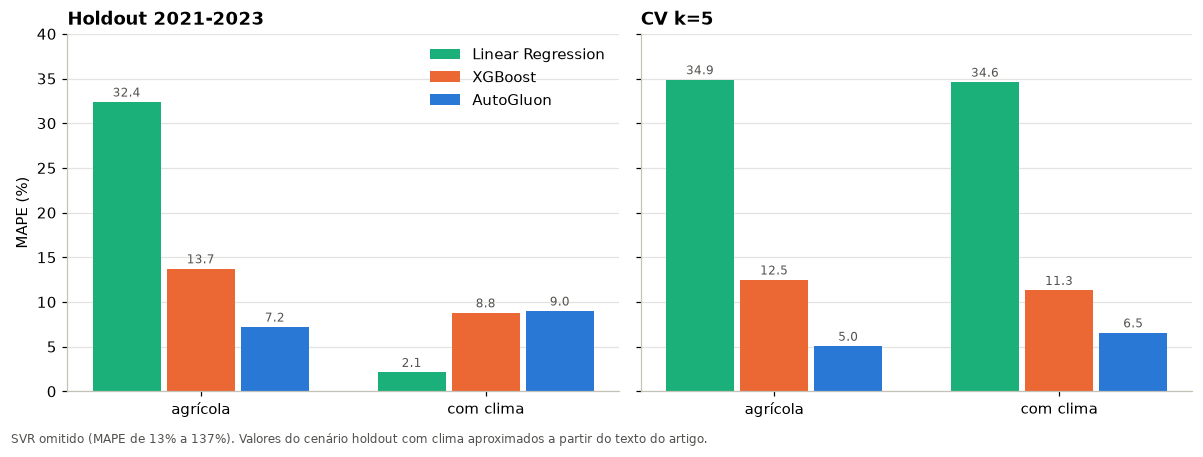

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
models = [("Linear Regression", AQUA), ("XGBoost", ORANGE), ("AutoGluon", BLUE)]
for ax, cenario in zip(axes, ["Holdout 2021-2023", "CV k=5"]):
    sub = comp[comp["Cenário"] == cenario].set_index("Features")
    x, w = np.arange(len(sub)), 0.26
    for i, (m, color) in enumerate(models):
        vals = sub[m].values
        bars = ax.bar(x + (i - 1) * w, vals, w * 0.92, color=color, label=m)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}", ha="center", fontsize=8, color="#52514e")
    ax.set_xticks(x, ["agrícola", "com clima"]); ax.set_title(cenario); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("MAPE (%)"); axes[0].set_ylim(0, 40); axes[0].legend(loc="upper right")
fig.text(0.01, -0.02, "SVR omitido (MAPE de 13% a 137%). Valores do cenário holdout com clima aproximados a partir do texto do artigo.",
         fontsize=8, color="#52514e")
fig.tight_layout(); fig.savefig(FIG / "comparacao_final.png", bbox_inches="tight"); plt.show()

In [28]:
# custo computacional total do notebook (treinos do AutoGluon)
total_cost = {
    "Cenário A (2 execuções)": sum(fit_time_A.values()),
    "Sensibilidade (8 execuções novas)": sensitivity["tempo real (s)"].sum() - fit_time_A["agri"],
    "Cenário B (10 execuções)": cv_summary["tempo total (s)"].sum(),
}
pd.Series(total_cost).round(0).rename("segundos")

Cenário A (2 execuções)              242.0
Sensibilidade (8 execuções novas)    387.0
Cenário B (10 execuções)             635.0
Name: segundos, dtype: float64

## 13. Discussão e análise crítica

**O AutoGluon é competitivo e, na maioria dos cenários, superior ao artigo.**
- **Holdout agrícola:** 7,20% contra 13,72% do XGBoost manual, quase metade do erro.
- **Validação cruzada:** 5,05% ± 0,48 (agrícola) e 6,55% ± 1,29 (com clima), contra 12,47% e 11,30% do XGBoost.
- **Holdout com clima:** 8,99%. Fica empatado com o XGBoost (8,79%, valor aproximado) e atrás da Regressão Linear do artigo
  (2,13%). Os dois valores do artigo são aproximações do texto, sem MAPE agregado publicado.
- **Regressão Linear com clima:** o 2,13% chama atenção. A nossa própria Regressão Linear padronizada, no mesmo split, fica
  em cerca de 25%, então esse número do artigo depende de uma configuração que não conseguimos reproduzir.

**O que o processo revela.**
- **O modelo final é um ensemble em 3 camadas** (`WeightedEnsemble_L3`). O Extra Trees com bagging é a base, com 56% do peso
  no cenário agrícola e 36% com clima. Uma rede neural e modelos da camada 2 (Random Forest e CatBoost treinados sobre as
  predições da camada 1) entram com pesos menores.
- **Os hiperparâmetros vencedores são os padrões do AutoGluon:** Extra Trees com 300 árvores e `max_leaf_nodes`=15000.
  O ganho vem da combinação de modelos, não de uma busca fina de hiperparâmetros.
- **Validação e teste divergem.**
  - O MAPE de validação do modelo escolhido (4,3%) é bem menor que o de teste (7,2%). A validação *out-of-fold* mistura
    anos, e o teste é o futuro (2021–2023), com mudança de distribuição.
  - O `WeightedEnsemble_L2`, uma camada a menos, foi um pouco melhor no teste (6,89% contra 7,20%). Ou seja, a terceira
    camada não pagou o custo aqui.
  - Modelos como a `NeuralNetTorch` têm erro de teste alto (25%) e mesmo assim recebem peso de 19%. O ensemble é escolhido
    pela validação, e a validação também erra.
- **Importância dos atributos.**
  - `Area harvested (ha)` domina: embaralhá-la piora o MAPE em mais de 200 p.p. Em seguida vêm `Yield (kg/ha)`
    (cerca de 27 p.p.) e o país.
  - Com clima, o peso do `Pais` dobra (14 → 29 p.p.) e a temperatura ganha relevância (12 p.p.), mas o erro de teste não
    melhora. É um sinal de que, com 13 observações por país, as variáveis climáticas ajudam o modelo a identificar o país
    mais do que a explicar a produção.
- **Por país:** Chile, Suriname, Uruguai e Equador concentram os maiores erros. Chile e Suriname dobram de erro com clima.
  São países de produção menor ou mais variável, o mesmo padrão relatado no artigo.

**Custo computacional.** O Cenário A leva cerca de 2 min por conjunto de atributos. O notebook inteiro, com sensibilidade,
sementes e validação cruzada (24 treinos), leva cerca de 30 min numa CPU de notebook. A predição é instantânea, abaixo de
0,4 s para os 36 pontos de teste. É bem mais caro que um XGBoost isolado, mas dispensa o ajuste manual.

**Vantagens.**
- Não há busca manual de modelo nem de hiperparâmetros: as decisões do grupo se resumem ao preset e ao tempo, ambos
  justificados na Seção 8.
- O `leaderboard` com erro de teste por modelo, os pesos do ensemble e a importância por permutação permitem auditar o resultado.
- O bagging e o stacking deram ganhos consistentes, mesmo com 120 linhas de treino.

**Limitações.**
- **O teste é pequeno.** São 36 pontos, e a variação entre sementes (± 1,06 p.p.) tem a mesma ordem das diferenças entre
  presets. Comparações finas não são conclusivas.
- **A semente varia só os modelos.** A divisão dos folds do bagging ficou fixa.
- **Com clima, o resultado piora** no holdout e na validação cruzada, ao contrário do que o artigo sugere para países com
  maior variabilidade climática.
- **Comparação com valores aproximados.** Os números do artigo no cenário holdout com clima são aproximações do texto,
  então essa comparação é a menos confiável.
- **O ensemble é menos interpretável** que um único XGBoost. A inspeção mostra a composição, mas não uma regra simples.
- **A validação cruzada aleatória mistura anos.** Ela é mais otimista que o holdout temporal, como mostra o erro menor do
  Cenário B. Isso também vale para o artigo, que usa o mesmo protocolo.


## 14. Conclusão

Partimos dos dados e da configuração experimental do artigo original e deixamos para o AutoGluon a seleção de modelos, os
hiperparâmetros e a combinação deles. O resultado supera o XGBoost manual do artigo em três dos quatro cenários: no holdout
agrícola, 7,2% contra 13,7%, e na validação cruzada, 5,1% contra 12,5% e 6,6% contra 11,3%. No quarto, o holdout com clima,
o AutoGluon fica empatado com o XGBoost (9,0% contra 8,8%, valor aproximado do artigo).

A inspeção mostrou que o ganho vem do ensemble com bagging e stacking, com o Extra Trees como base, e não de hiperparâmetros
especiais. A área colhida é de longe o atributo mais importante. As variáveis climáticas, com tão poucas observações por país,
parecem servir mais como identificador do país que como explicação da produção.

Próximos passos, sem exigir dados adicionais:
- variar também a divisão dos folds;
- usar uma validação temporal dentro do AutoGluon, em vez do k-fold aleatório, para que a validação reflita a previsão do futuro;
- testar a generalização por país com leave-one-country-out.
